# Final training — tuned settings vs. baseline (scratch ResNet, Kaggle)

Retrains the best setting from grid search, random search and Optuna, plus the original Experiment 9 setting, for the **full 100 epochs**. All models use the same seed, data and recipe, so their accuracies can be compared directly. The winner is chosen on validation accuracy, then every model is evaluated on the test set for reporting.

**Before running:**
1. **Accelerator: GPU T4 x2** and **Internet: On** (right-hand panel).
2. **Attach the tuning results:** **Add Input → Your Work →** the tuning notebook **→ Notebook Output Files**. The notebook looks for `grid_trials.csv`, `random_trials.csv` and `optuna_trials.csv`.
3. Click **Save Version → Save & Run All (Commit)**. Expect about 1 hour per model, about 4 hours in total.

If the session stops early, attach this notebook's own output as input as well and run it again. Finished models are skipped.

In [1]:
REPO_URL = "https://github.com/TokaElsaayed/Deep-project.git"
BRANCH = "hyperparameter-tuning"
REPO_DIR = "/tmp/Deep-project"
TUNING_DIR = "/kaggle/working/hyperparameter_tuning"   # final models go to TUNING_DIR/final
EPOCHS = 100

In [2]:
!nvidia-smi
import torch
print(torch.__version__, "CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Turn on a GPU accelerator (GPU T4 x2) in the notebook settings."

Sun Nov  1 17:57:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!rm -rf {REPO_DIR}
!git clone --depth 1 -b {BRANCH} {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!git log -1 --oneline
!pip install -q optuna datasets

Cloning into '/tmp/Deep-project'...
remote: Enumerating objects: 97, done.
remote: Counting objects: 100% (97/97), done.
remote: Compressing objects: 100% (93/93), done.
remote: Total 97 (delta 4), reused 74 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (97/97), 48.45 MiB | 19.70 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/tmp/Deep-project
65257bf (grafted, HEAD -> hyperparameter-tuning, origin/hyperparameter-tuning) Merge final retraining into tune_scratch_resnet.py as --method final


## Copy the tuning results (and any finished final models) from the attached inputs

In [4]:
import glob, os, shutil
os.makedirs(TUNING_DIR, exist_ok=True)
sources = sorted({os.path.dirname(p) for p in glob.glob("/kaggle/input/**/*_trials.csv", recursive=True)})
for folder in sources:
    shutil.copytree(folder, TUNING_DIR, dirs_exist_ok=True)   # includes final/ from an earlier run of this notebook
    print("Copied", folder)
assert sources, "No tuning results found. Attach the tuning notebook's output (Add Input → Your Work)."
print(sorted(os.listdir(TUNING_DIR)))

Copied /kaggle/input/notebooks/carolleid/notebook7edfc21ea0/hyperparameter_tuning
['best_hyperparameters.json', 'best_score_comparison.png', 'comparison.csv', 'comparison.md', 'grid_trials.csv', 'optuna_study.db', 'optuna_trials.csv', 'random_trials.csv', 'search_space_coverage.png']


In [5]:
# Shows which settings will be trained.
!python src/training/tune_scratch_resnet.py --method final --output-dir {TUNING_DIR} --epochs {EPOCHS} --dry-run

baseline: max_lr=0.002, weight_decay=0.03
    grid: max_lr=0.001, weight_decay=0.03 (short-run val acc 8.57%)
  random: max_lr=0.001194, weight_decay=0.02821 (short-run val acc 8.23%)
  optuna: max_lr=0.001681, weight_decay=0.08927 (short-run val acc 8.90%)


## Train and evaluate (about 1 hour per model)

In [6]:
!python src/training/tune_scratch_resnet.py --method final --output-dir {TUNING_DIR} --epochs {EPOCHS}

baseline: max_lr=0.002, weight_decay=0.03
    grid: max_lr=0.001, weight_decay=0.03 (short-run val acc 8.57%)
  random: max_lr=0.001194, weight_decay=0.02821 (short-run val acc 8.23%)
  optuna: max_lr=0.001681, weight_decay=0.08927 (short-run val acc 8.90%)

[baseline] training 100 epochs with max_lr=0.002, weight_decay=0.03
Loading dataset 'Multimodal-Fatima/CUB_train', split='train' ...
README.md: 100%|███████████████████████████| 7.16k/7.16k [00:00<00:00, 16.5MB/s]

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes: ▊|  233MB, 19.2M
data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes: ▉|  256MB, 22.5M
data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes: █|  285MB, 24.3M
data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file: 100%|█|  287MB

data/train-00001-of-00002-ae08e95fea856c(…): downloading bytes: ▋|  222MB, 18.4M
data/train-00001-of-00002-ae08e95fea856c(…): downloading bytes: ▉|  284MB, 24.7M
data/train-00001-of-00002-ae08e95fea856

## Results

# Final training: tuned settings vs. baseline (scratch ResNet)

Every model was trained for 100 epochs with the same seed, data and recipe; only max_lr and weight_decay differ. The selected model has the highest validation accuracy. The test split was used only to report results, not to choose between models.

| Settings from | max_lr | weight_decay | Short-run val acc | Best val acc | Best epoch | Test acc | Test acc (flip TTA) | Training time (min) |
|---|---|---|---|---|---|---|---|---|
| Baseline (Experiment 9 settings) | 0.002 | 0.03 | — | 53.06% | 91 | 56.96% | 57.56% | 60 |
| Grid search | 0.001 | 0.03 | 8.57% | 52.39% | 92 | 55.76% | 55.78% | 61 |
| Random search | 0.001194 | 0.02821 | 8.23% | 52.61% | 89 | 55.92% | 56.04% | 61 |
| Optuna (TPE + pruning) **(selected)** | 0.001681 | 0.08927 | 8.90% | 53.95% | 90 | 57.70% | 58.44% | 60 |

The recorded Experiment 9 run reached 53.39% validation and 56.04% test accuracy (`outputs/baseline/README.md`). The baseline row above retrains those settings on the same hardware as the tuned runs.

Plot: `final_validation_curves.png`.


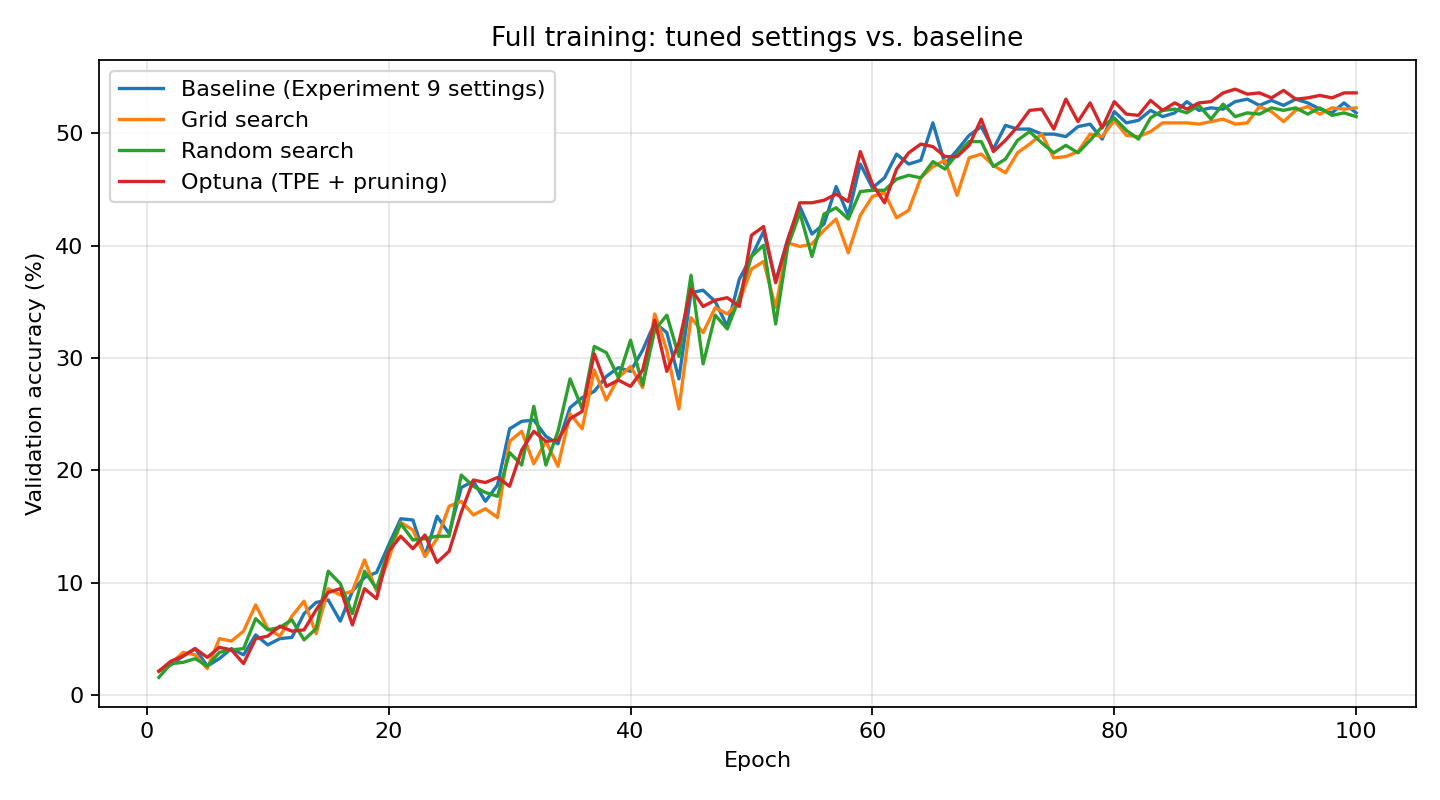

In [7]:
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{TUNING_DIR}/final/final_comparison.md").read()))
display(Image(f"{TUNING_DIR}/final/final_validation_curves.png"))